# KiDS-450 weak-lensing mass mapping


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `kids450_weak_lensing_mass` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：positions (1, 16625, 2) float64：Right ascension and declination in degrees, J2000.；ellipticity (1, 16625, 2) float64：Dimensionless lensfit e1/e2 shape measurements, in supplied sky basis.；weight (1, 16625) float64：Dimensionless inverse-variance lensfit weights.；multiplicative_bias (1, 16625) float64：Dimensionless independently calibrated ensemble shear bias m.；psf_ellipticity (1, 16625, 2) float64：Dimensionless independent PSF e1/e2 model diagnostics at galaxy positions.。恢复目标：E-mode convergence和B-mode图，无量纲。

获取模型：弱透镜spin-2 Fourier核将E/B convergence映射为shear，catalogue提供有噪shape采样。实际恢复算法：solvers.grid_catalogue/solve/reconstruct：校准binning、Kaiser-Squires FFT逆及固定2pixel分辨率。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:54为原始标准map，没有真实宇宙质量图。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：kids450_weak_lensing_mass.ipynb单元0：5. Results；kids450_weak_lensing_mass.ipynb单元2：Fresh reconstruction, comparisons and sensitivity；kids450_weak_lensing_mass.ipynb单元3有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元3（从0计数）。代码单元3个，带execution_count的3个，保存PNG输出4幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem


### Problem, observations and physics

Weak lensing constrains projected mass through coherent galaxy distortions. On this one-degree tangent-plane patch, $x=(\mathrm{RA}-129)\cos(-0.5^\circ)$ and $y=\mathrm{Dec}+0.5$ are angular offsets. Weighted ensemble calibration gives $\gamma_j=\sum w e_j/\sum w(1+m)$ per pixel, where $e_j$ is a lensfit shape component, $w$ its inverse-variance weight and $m$ its independent image-simulation calibration. The Fourier kernels $P_1=(k_x^2-k_y^2)/(k_x^2+k_y^2)$ and $P_2=2k_xk_y/(k_x^2+k_y^2)$ map E/B convergence to shear. The zero Fourier mode is unobservable (mass-sheet degeneracy).

The original Lenspack KS93 result is an algorithm reference, not a measured dark-matter truth. Gaussian smoothing suppresses shape noise. The B mode, independent PSF shapes, 32 orientation randomizations and calibration omission bound the interpretation. Nyquist lines on the even grid undergo the original real-part projection; forward-closure plots disclose that numerical limitation rather than claiming exact invertibility for all modes.

## 2. Data

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| positions | (1, 16625, 2) | float64 | Right ascension and declination in degrees, J2000. |
| ellipticity | (1, 16625, 2) | float64 | Dimensionless lensfit e1/e2 shape measurements, in supplied sky basis. |
| weight | (1, 16625) | float64 | Dimensionless inverse-variance lensfit weights. |
| multiplicative_bias | (1, 16625) | float64 | Dimensionless independently calibrated ensemble shear bias m. |
| psf_ellipticity | (1, 16625, 2) | float64 | Dimensionless independent PSF e1/e2 model diagnostics at galaxy positions. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Survey | KiDS-450 / ESO DR3.1 | dimensionless | Real VST/OmegaCAM r-band lensfit catalogue. |
| RA centre | 129.0 | degree | Tangent-plane origin. |
| Declination centre | -0.5 | degree | Tangent-plane origin. |
| RA range | [128.5, 129.5) | degree | Fixed outer observation boundaries. |
| Declination range | [-1, 0) | degree | Fixed outer observation boundaries. |
| Target grid | 64 by 64 | pixel | North rows and east columns, increasing coordinates. |
| Coordinate conversion | x=(RA-129.0)cos(-0.5 degrees), y=Dec+0.5 | degree | Constant-declination small-field projection. |
| Grid extent | [-0.5cos(-0.5 degrees),0.5cos(-0.5 degrees)] by [-0.5,0.5] | degree | Gridding uses projected boundaries; FFT uses equal pixel spacings (flat-sky aspect approximation of 0.0038%). |
| Sampling | weighted cell mean | dimensionless | Upper boundary excluded by catalogue selection; empty cell has shear zero. |
| Source selection | 0.1<=zbest<=0.9; Mask=0; FitClass=0; weight>0 | dimensionless | Reliable source shapes and photometric-redshift range, already applied. |
| Shear calibration | ensemble division by sum w(1+m) | dimensionless | Never divide each individual galaxy by its own 1+m. |
| Uncertainty | intrinsic shapes and measurement noise | dimensionless | No homogeneous Gaussian pixel-noise variance is asserted. |
| Fourier convention | exp(-2 pi i k dot x); inverse 1/(64*64) | dimensionless | NumPy DFT, periodic boundary, zero DC, real-part projection. |

## 3. Physics

### Quantified original-code validation: DC and even-grid Nyquist limits

A subsequent independent unmodified Lenspack ks93/ks93inv investigation is archived in private kids_nyquist_investigation.json. DC is removed before all following loss measurements. On bound unsmoothed shear, the relative round-trip residual is0.11671448696328429, energy fraction0.013622271467102659; thus the raw arbitrary real-shear map is NOT strictly invertible. On the actual sigma2-pixel output resolution, the residual is5.100980825832628e-7, energy fraction2.602000538551212e-13, maximum component residual5.895273347267249e-8. This small post-filter quantity is distinct from the unobservable DC shear components(-0.002018809126667842,0.0032107191158432307).

A random real shear field likewise has0.11794703832818561 relative raw loss but4.7408767102097243e-7 after sigma2 filtering. An analytic E mode cos(pi*x)*cos(2*pi*3*y/64) gives p1=(32^2-3^2)/(32^2+3^2)=0.9825750242013552; its source-convention E round-trip amplitude is p1^2=0.9654536781842938, agreeing with a3.4546321815706% loss. This is the mixed-Nyquist real-part projection, not the DC mass-sheet degeneracy. Source convention is retained; analytic/adjoint checks do not imply exact inversion for all discrete real modes. B and orientation noise remain comparable to E, and no independently significant dark-matter detection is claimed.

For Fourier frequency $(k_x,k_y)\ne(0,0)$, define $P_1=(k_x^2-k_y^2)/|k|^2$ and $P_2=2k_xk_y/|k|^2$. Calibrated shear components $\gamma_1,\gamma_2$ and projected convergence modes satisfy

$$
\widehat\kappa_E=P_1\widehat\gamma_1+P_2\widehat\gamma_2,\qquad
\widehat\kappa_B=-P_2\widehat\gamma_1+P_1\widehat\gamma_2.
$$

Convergence and shear are dimensionless; angular coordinates are degrees on the tangent plane. Set the DC coefficient to zero. The real-part projection on an even discrete grid also discards some mixed-Nyquist structure, a separate numerical effect quantified below.

## 4. Method

### Visual contract and evidence roles

The main plate shows native observations and fresh physical reconstruction with honest common scales. Mechanism panels compare actual algorithm components and ablations; sensitivity panels quantify regularization/detail tradeoffs. References are independently captured original-code measurements on exactly these observations, never relabeled as fresh computation. Every displayed fresh variant is calculated in this execution. The private gallery exports vector PDF/SVG and high-resolution PNG from these exact arrays.

Calibrate weighted galaxy shapes on the fixed 64 by 64 patch, apply the local KS93 Fourier inverse, then the selected two-pixel Gaussian smoothing. The B mode, PSF-shape map, 32 randomized-orientation maps and calibration-omission result are separate freshly computed diagnostics. Their amplitudes must be interpreted alongside E, rather than assigning every E feature to a significant mass detection.

## 5. Results




In [1]:
from pathlib import Path
import os,sys,time,json
for variable in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS']: os.environ[variable]='1'
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.preprocessing import load_data
from src.main import run
from src.visualization import review,metrics
print('Kernel executable:',sys.executable)
print('NumPy version:',np.__version__)
started=time.perf_counter()
data=load_data(ROOT/'data/raw_data.npz')
fresh=run(ROOT/'data/raw_data.npz',ROOT/'output/reconstruction.npz')
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as f: upstream={k:f[k].copy() for k in f.files}
for key in fresh:
    ncc,nrmse=metrics(fresh[key],upstream[key])
    print(f'{key}: NCC={ncc:.16g}, dynamic-range NRMSE={nrmse:.16g}')
print(f'Fresh standard reconstruction: {time.perf_counter()-started:.3f} s')
# Distinct source-run scalar measurements are retained without redundant large arrays.
with np.load(ROOT/'notebooks/reference_outputs/upstream_summary.npz',allow_pickle=False) as f:
    original_summary={k:float(f[k][0]) for k in f.files}
fresh_summary={}
for key,array in fresh.items():
    value=array.astype(float)
    for statistic,number in [('mean',value.mean()),('rms',np.sqrt(np.mean(value**2))),('minimum',value.min()),('maximum',value.max())]:
        fresh_summary[key+'_'+statistic]=np.array([number])
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_summary.npz',**fresh_summary)
display(Markdown('| Measurement | Original code run | Fresh local run |\n| --- | ---: | ---: |\n'+'\n'.join(f'| {key} | {number:.10g} | {float(fresh_summary[key][0]):.10g} |' for key,number in original_summary.items())))


Kernel executable: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
NumPy version: 2.4.6
reconstruction: NCC=1, dynamic-range NRMSE=3.708387311774689e-17
bmode: NCC=1, dynamic-range NRMSE=4.019121957954137e-17
Fresh standard reconstruction: 0.013 s


| Measurement | Original code run | Fresh local run |
| --- | ---: | ---: |
| reconstruction_mean | 5.421010862e-19 | 6.505213035e-19 |
| reconstruction_rms | 0.02392501034 | 0.02392501034 |
| reconstruction_minimum | -0.1220564232 | -0.1220564232 |
| reconstruction_maximum | 0.1135216143 | 0.1135216143 |
| bmode_mean | -2.168404345e-19 | -7.589415207e-19 |
| bmode_rms | 0.0233945998 | 0.0233945998 |
| bmode_minimum | -0.07894092345 | -0.07894092345 |
| bmode_maximum | 0.1201020842 | 0.1201020842 |

### Fresh reconstruction, comparisons and sensitivity

The following four figures are produced from local modules. The metric table distinguishes algorithm agreement from observational-consistency diagnostics. A low discrepancy or agreement with a standard method does not establish physical accuracy when independent truth is unavailable.


### 01 mass maps

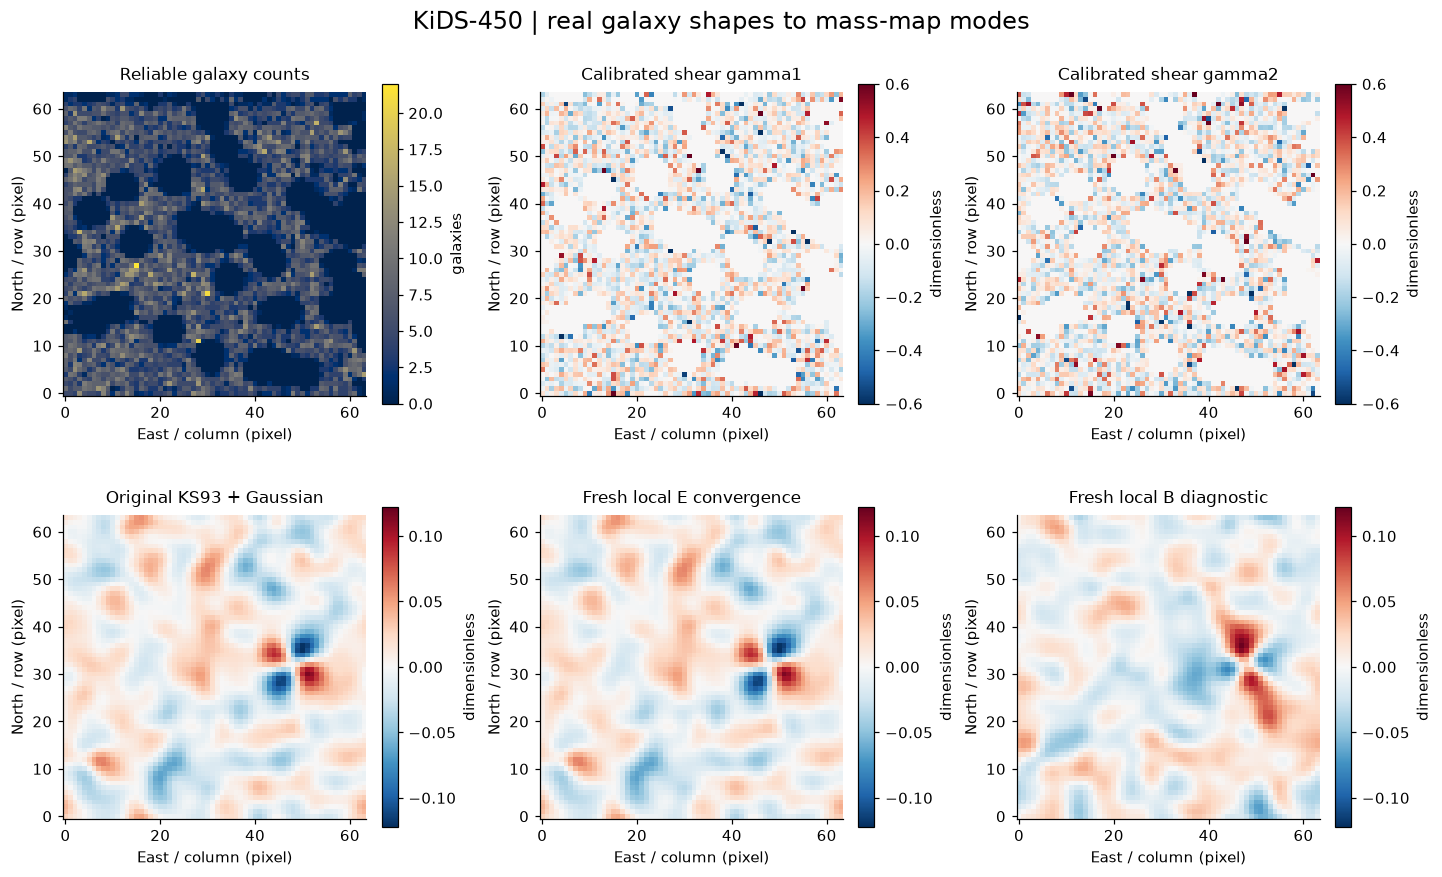

### 02 smoothing

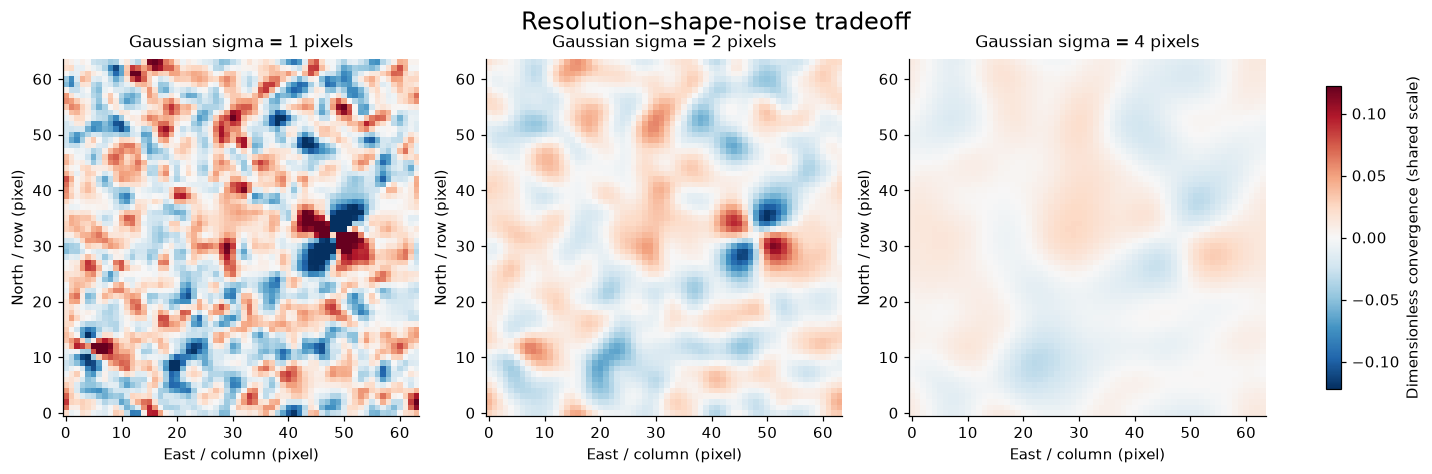

### 03 null psf

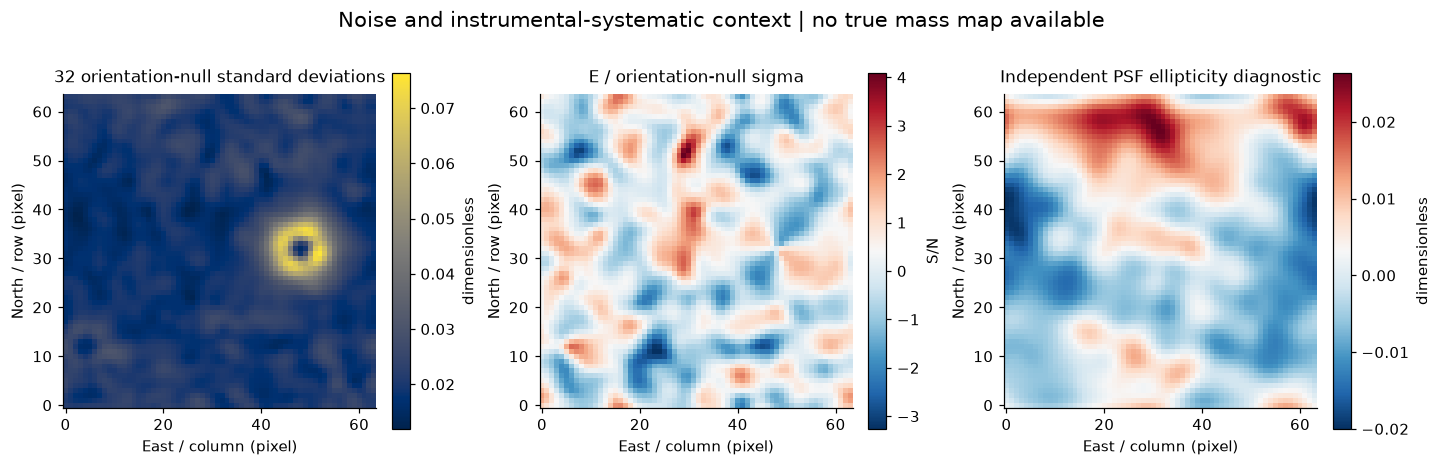

### 04 mechanism

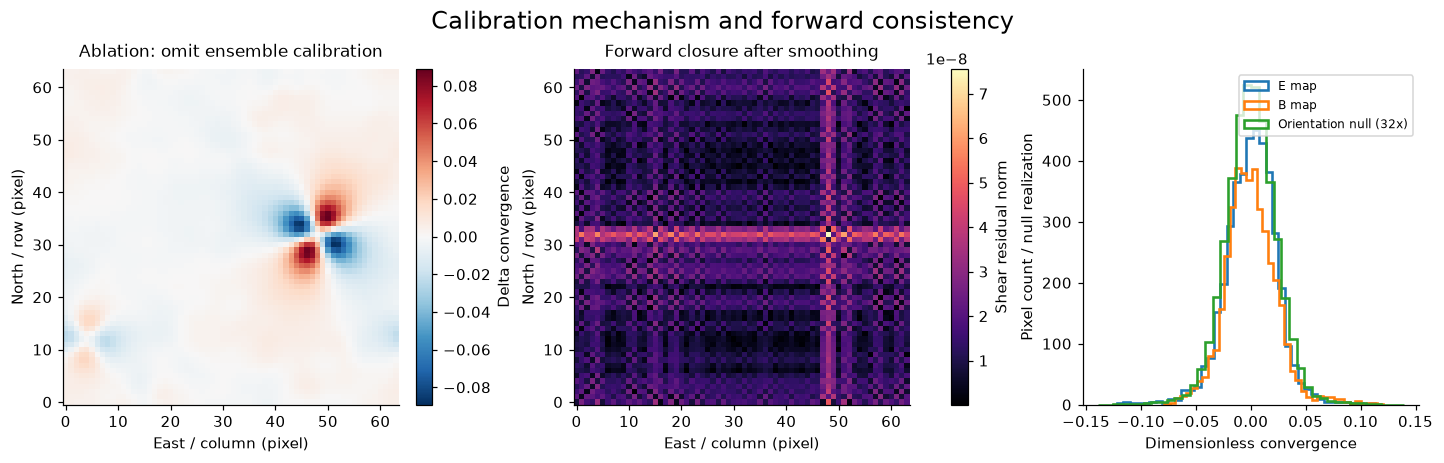

| experiment | E_rms | B_rms | NRMSE_vs_original |
| --- | --- | --- | --- |
| sigma=1.0 | 0.047335516 | 0.045837297 | 0.13267741 |
| sigma=2.0 | 0.02392501 | 0.0233946 | 3.7083873e-17 |
| sigma=4.0 | 0.010940303 | 0.011883228 | 0.070786287 |
| no ensemble calibration | 0.018606836 | 0.017736269 | 0.051464128 |

Full active reconstruction plus experiments/figures: 1.369 s


In [2]:
figures,table,source_arrays=review(data,upstream)
for figure_name,figure in figures:
    display(Markdown('### '+figure_name.replace('_',' ')))
    display(figure)
    plt.close(figure)
keys=list(table[0])
lines=['| '+' | '.join(keys)+' |','| '+' | '.join(['---']*len(keys))+' |']
for row in table:
    lines.append('| '+' | '.join(str(row.get(k,'')) if not isinstance(row.get(k),float) else f'{row[k]:.8g}' for k in keys)+' |')
display(Markdown('\n'.join(lines)))
print(f'Full active reconstruction plus experiments/figures: {time.perf_counter()-started:.3f} s')
# Optional export path is private and supplied by the maintainer execution environment.
gallery=os.environ.get('IMAGING_PRIVATE_GALLERY')
if gallery:
    destination=Path(gallery)/ROOT.name;destination.mkdir(parents=True,exist_ok=True)
    for name,figure in figures:
        for ext in ['png','pdf','svg']:figure.savefig(destination/(name+'.'+ext),bbox_inches='tight')
    np.savez_compressed(destination/'figure_source_arrays.npz',**source_arrays)
    (destination/'experiment_metrics.json').write_text(json.dumps(table,indent=2,allow_nan=False))

In [3]:
import subprocess
result=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
print((ROOT/'output/judge_report.json').read_text())
assert result.returncode==0,result.stderr

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 1.0,
    "reconstruction_nrmse": 3.708387311774689e-17,
    "bmode_ncc": 1.0,
    "bmode_nrmse": 4.019121957954137e-17,
    "relative_shear_residual": 5.100980825848082e-07
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "bmode_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "bmode_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "relative_shear_residual": {
      "comparison": "<=",
      "boundary": 0.0001
    }
  },
  "errors": []
}



## 6. Conclusion

### Evaluation and conclusion

The standalone Judge below evaluates the fresh file. Physical and mathematical validation are separate tests under `test/`. The spatial plates show what is actually constrained, while the ablations and residuals expose where method assumptions matter. Interpret the output as the declared regularized standard-method reconstruction of the supplied real observations; do not reinterpret it as independently measured truth.
